# The coastline paradox

How long is the coast of Great Britain? Lewis Fry Richardson measured coasts with dividers: set them to a length r,
walk them along the coast from point to point, and count the steps. The shorter the ruler, the more of the coast's
bays and headlands it follows, and the longer the coast becomes, without a limit in sight. For many coasts, the
length grows as a power of the ruler, L ∝ r^(1 − D). Mandelbrot called D the fractal dimension of the coast and
quoted D ≈ 1.25 from Richardson's measurements of Britain's west coast. A smooth curve has D = 1.

Here, the dividers are first checked on the Koch snowflake, whose dimension is known exactly, and then walked along
the coast of Great Britain.

![The coast of Great Britain, measured with dividers of 80 and 20 km](../_static/gallery/coastline-paradox.png){.result}

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import planex as px

## The dividers

`dividers` walks along a closed polyline. From the current point, the next point is where the line first leaves
the circle of radius r around it, and the walk steps there. When less than r is left, the remaining distance to the
start is added. A point that lies within 10⁻⁹ r of the circle counts as on it, since the vertices of the Koch
snowflake lie exactly on the circles.

In [2]:
def dividers(points, r):
    line = np.vstack([points, points[:1]])
    here, i, walk = line[0], 0, [line[0]]
    while True:
        far = np.nonzero(np.hypot(*(line[i + 1:] - here).T) >= r * (1 - 1e-9))[0]
        if len(far) == 0:
            return (len(walk) - 1) * r + math.dist(line[-1], here), np.array(walk)
        i += far[0]
        a, b = line[i], line[i + 1]
        u, f = b - a, a - here
        p, q = u @ f / (u @ u), (f @ f - r**2) / (u @ u)
        here = a + (-p + math.sqrt(max(p * p - q, 0))) * u
        walk.append(here)

## A check: the Koch snowflake

The Koch snowflake starts from an equilateral triangle and puts a bump on the middle third of every edge, again and
again. Each round multiplies the perimeter by 4/3, so dividers of length 3^(−m) measure 3 · (4/3)^m, and
D = log 4 / log 3, about 1.2619. The example builds six rounds, 12288 edges, as a planex2d face. Its perimeter and
area agree with the series of the construction:

In [3]:
def koch(a, b, rounds):
    if rounds == 0:
        return [a]
    third = (b - a) / 3
    turn = np.array([[0.5, math.sqrt(3) / 2], [-math.sqrt(3) / 2, 0.5]])
    c, e = a + third, a + 2 * third
    d = c + turn @ third
    return [p for s, t in ((a, c), (c, d), (d, e), (e, b)) for p in koch(s, t, rounds - 1)]


corners = [np.array((0.0, 0.0)), np.array((1.0, 0.0)), np.array((0.5, math.sqrt(3) / 2))]
rounds = 6
points = np.array([p for k in range(3) for p in koch(corners[k], corners[(k + 1) % 3], rounds)])
flake = px.Face([px.FromPolyline(points, closed=True)])
triangle = math.sqrt(3) / 4
area = triangle * (1 + sum(3 * 4 ** (n - 1) / 9**n for n in range(1, rounds + 1)))
print(len(flake.edges), "edges, perimeter", flake.outer.mass, "exact", 3 * (4 / 3) ** rounds)
print("area", flake.mass, "exact", area)

12288 edges, perimeter 16.855967078186733 exact 16.855967078189295
area 0.6908178956345367 exact 0.6908178956345377


The dividers give the exact lengths, and the slope of log L over log r gives D:

In [4]:
rulers = [3.0**-m for m in range(1, 6)]
lengths = [dividers(points, r)[0] for r in rulers]
print("lengths", [round(L, 12) for L in lengths])
print("exact  ", [round(3 * (4 / 3) ** m, 12) for m in range(1, 6)])
slope = np.polyfit(np.log(rulers), np.log(lengths), 1)[0]
print("D", 1 - slope, "exact", math.log(4) / math.log(3))

lengths [4.0, 5.333333333333, 7.111111111111, 9.481481481481, 12.641975308642]
exact   [4.0, 5.333333333333, 7.111111111111, 9.481481481481, 12.641975308642]
D 1.261859507142915 exact 1.2618595071429148


## The coast of Great Britain

The coast is Great Britain's outline from the 1:10m coastline of [Natural Earth](https://www.naturalearthdata.com),
which is in the public domain. It is projected to kilometers around the middle of the island and stored as
[britain-coast.csv](britain-coast.csv) next to this page: 3706 points, about 2 km apart.

In [5]:
coast = np.loadtxt("britain-coast.csv", delimiter=",", comments="#")
island = px.Face([px.FromPolyline(coast, closed=True)])
print(len(coast), "points, coast", island.outer.mass, "km")

3706 points, coast 7319.654743722943 km


Walked with dividers from 5 to 160 km, the coast grows from about 2600 km to more than 6000 km. In a log-log plot, the
lengths lie close to a line, and its slope gives D near Mandelbrot's 1.25:

ruler 5 km: coast 6142 km
ruler 10 km: coast 5410 km
ruler 20 km: coast 4588 km
ruler 40 km: coast 3925 km
ruler 80 km: coast 3076 km
ruler 160 km: coast 2565 km
D 1.2562510009265924


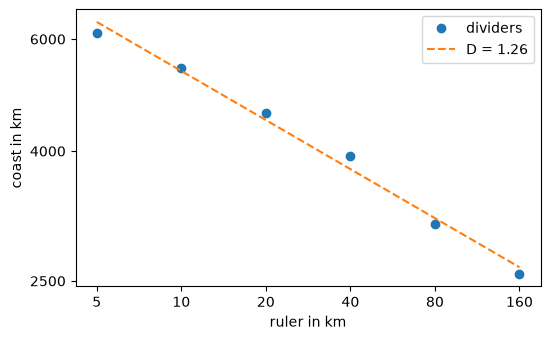

In [6]:
rulers = [5, 10, 20, 40, 80, 160]
walks = {r: dividers(coast, r) for r in rulers}
lengths = [walks[r][0] for r in rulers]
for r, L in zip(rulers, lengths):
    print("ruler", r, "km: coast", round(L), "km")
slope, offset = np.polyfit(np.log(rulers), np.log(lengths), 1)
print("D", 1 - slope)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.loglog(rulers, lengths, "o", label="dividers")
ax.loglog(rulers, np.exp(offset) * np.array(rulers, dtype=float) ** slope, "--", label=f"D = {1 - slope:.2f}")
ax.minorticks_off()
ax.set_xticks(rulers, [str(r) for r in rulers])
ax.set_yticks([2500, 4000, 6000], ["2500", "4000", "6000"])
ax.set_xlabel("ruler in km")
ax.set_ylabel("coast in km")
ax.legend();

Below a few kilometers, the data itself sets the limit: with points about 2 km apart, the polyline is the coast at
that resolution, and its own length, 7320 km, is what the shortest dividers approach. A finer map would give a longer
coast again.

The two walks of 80 and 20 km over the island:

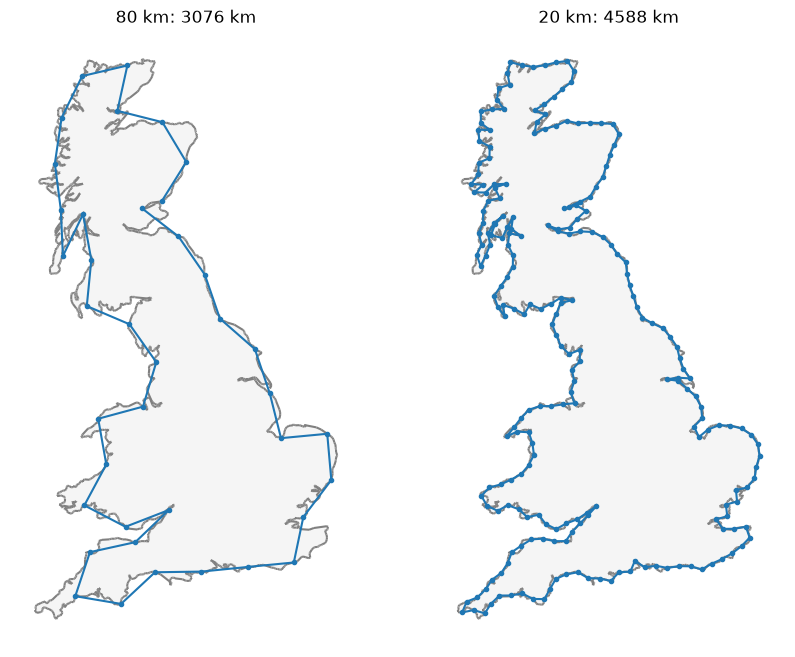

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 8))
for ax, r in zip(axes, (80, 20)):
    island.Plot(ax=ax, face_col="whitesmoke", line_col="gray", legend=False)
    walk = walks[r][1]
    ax.plot(walk[:, 0], walk[:, 1], "o-", color="tab:blue", markersize=3)
    ax.set_title(f"{r} km: {round(walks[r][0])} km")
    ax.axis("off")

In [8]:
import sys
sys.path.insert(0, "..")
from gallery import save_figure
save_figure(fig, "coastline-paradox", bare=True)